In [190]:
import pandas as pd
import numpy as np
import seaborn as sns
import torch
import matplotlib.pyplot as plt

In [191]:
df = pd.read_csv("09-iris.csv")

In [192]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [193]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [194]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [195]:
df["Species"].value_counts()

,count
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


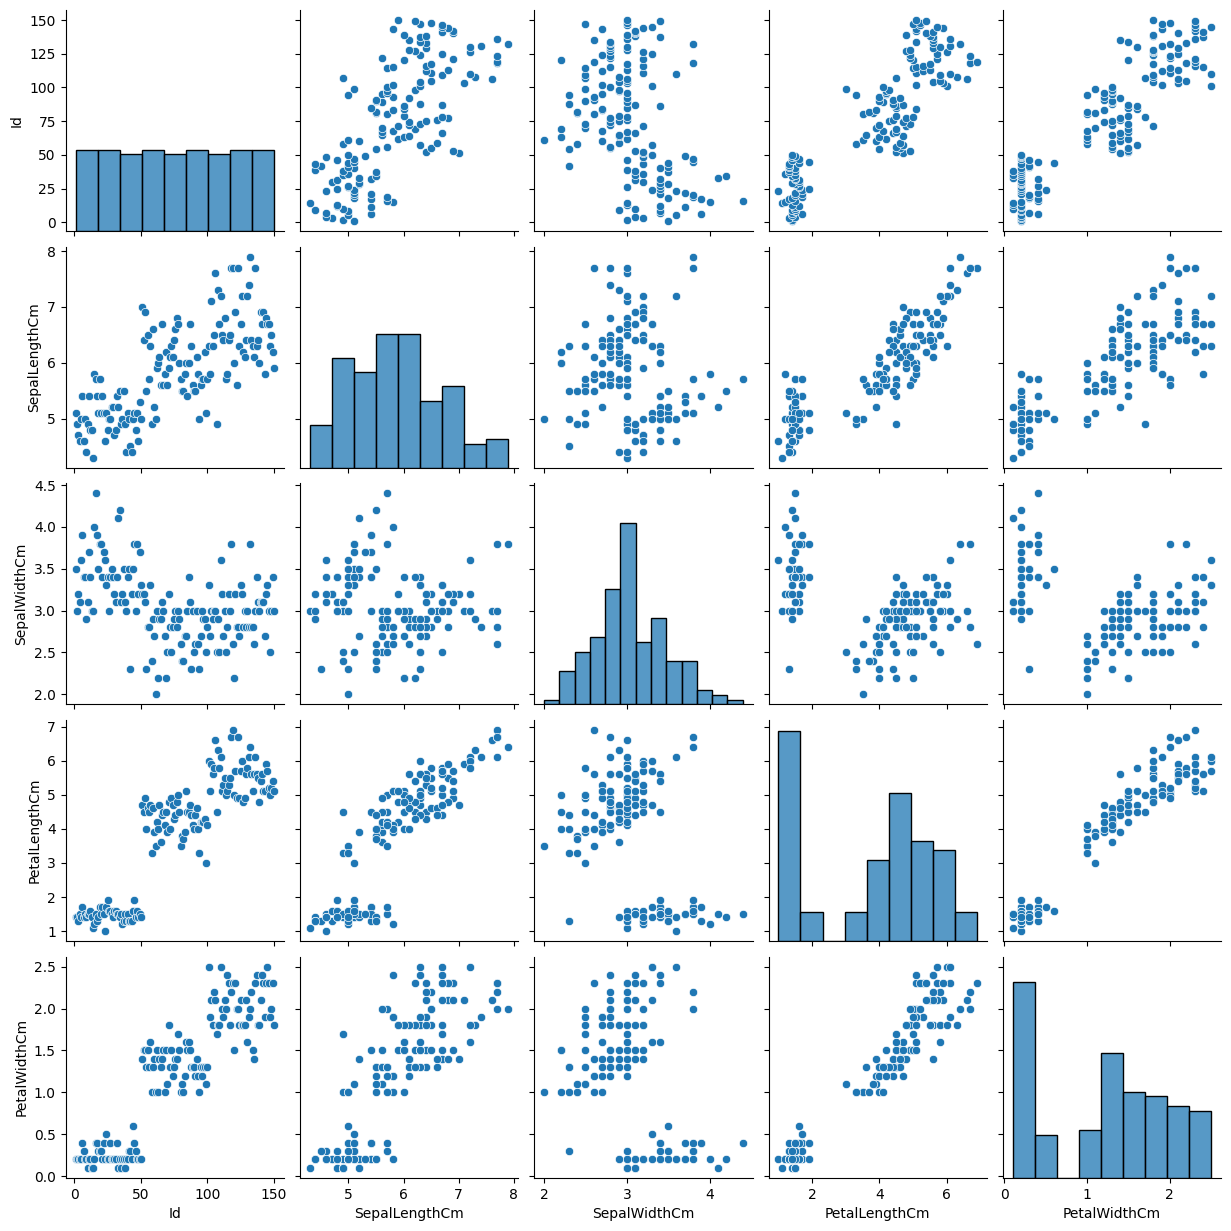

In [196]:
sns.pairplot(df)
plt.show()

In [197]:
df = df.drop("Id", axis=1)

In [198]:
df

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


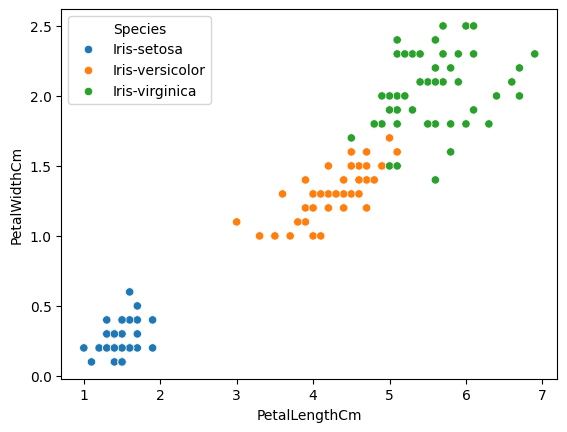

In [199]:
sns.scatterplot(data=df, x="PetalLengthCm", y="PetalWidthCm", hue="Species")
plt.show()

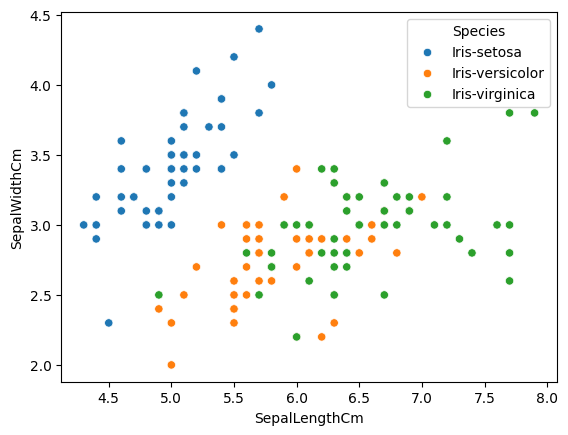

In [200]:
sns.scatterplot(data=df, x="SepalLengthCm", y="SepalWidthCm", hue="Species")
plt.show()

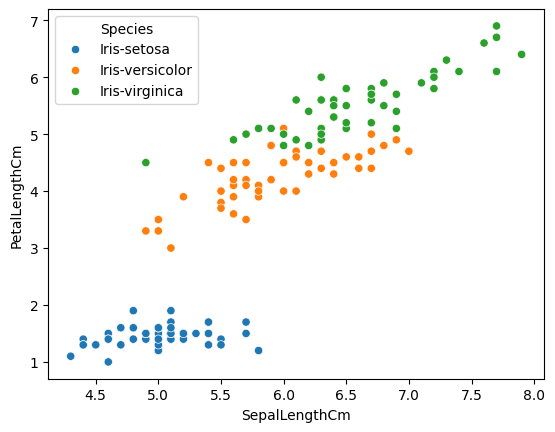

In [201]:
sns.scatterplot(data=df, x="SepalLengthCm", y="PetalLengthCm", hue="Species")
plt.show()

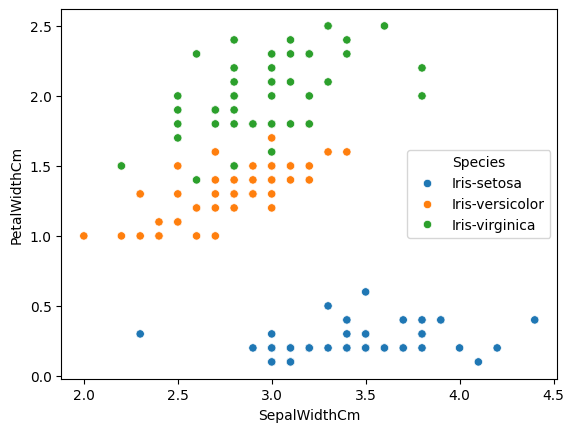

In [202]:
sns.scatterplot(data=df, x="SepalWidthCm", y="PetalWidthCm", hue="Species")
plt.show()

In [203]:
X = df.drop("Species", axis=1).values
y = df["Species"].values

In [204]:
# y'deki kategorik değişkenler numeriğe çevirilmeli.

In [205]:
# label encoding

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

In [206]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [207]:
# burada bir data leakage olabilir. Önce train test ayrımı yapılmalıydı.

In [208]:
from sklearn.model_selection import train_test_split

In [209]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [210]:
y_test

array([0, 2, 1, 1, 0, 1, 0, 0, 2, 1, 2, 2, 2, 1, 0, 0, 0, 1, 1, 2, 0, 2,
       1, 2, 2, 1, 1, 0, 2, 0])

In [211]:
y_train

array([0, 2, 1, 0, 1, 2, 1, 2, 2, 2, 2, 1, 1, 1, 1, 0, 0, 2, 2, 0, 1, 0,
       2, 0, 1, 2, 2, 0, 2, 0, 0, 1, 1, 0, 2, 2, 1, 1, 2, 1, 0, 1, 0, 2,
       0, 0, 2, 0, 0, 0, 0, 1, 2, 1, 0, 2, 1, 2, 0, 2, 0, 1, 2, 0, 1, 1,
       2, 1, 1, 2, 0, 0, 0, 2, 1, 2, 1, 2, 2, 1, 0, 2, 1, 0, 2, 0, 2, 1,
       1, 0, 1, 2, 0, 0, 2, 2, 2, 1, 2, 0, 2, 1, 2, 2, 0, 1, 1, 1, 1, 1,
       0, 2, 1, 1, 0, 0, 0, 0, 1, 0])

In [212]:
df3 = pd.DataFrame({
    "y_train": pd.Series(y_train),
    "y_test": pd.Series(y_test)
})

In [213]:
df3.describe()

,y_train,y_test
count,120.00000,30.000000
mean,1.00000,1.000000
std,0.81992,0.830455
min,0.00000,0.000000
25%,0.00000,0.000000
50%,1.00000,1.000000
75%,2.00000,2.000000
max,2.00000,2.000000


In [214]:
# stratify=y ifadesinin dağılımı koruduğunu görebiliyorum.

In [215]:
X_train = torch.tensor(X_train, dtype=torch.float32) # forward propagation modeli float32 kabul ediyor.
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long) # cross entropy loss fonksiyonu icin.
y_test = torch.tensor(y_test, dtype=torch.long)

In [216]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape # CrossEntropyLoss'un kabul etmesi sebebiyle unsqueeze yapmamıza gerek yok.

(torch.Size([120, 4]),
 torch.Size([30, 4]),
 torch.Size([120]),
 torch.Size([30]))

In [217]:
# from torch import nn


# class IrisClassifier(nn.Module):
#   def __init__(self):
#     super().__init__()

#     self.layer1 = nn.Linear(in_features=4, out_features=16)
#     self.layer2 = nn.Linear(in_features=16, out_features=16)
#     self.layer3 = nn.Linear(in_features=16, out_features=3)

#     self.relu = nn.ReLU()

#   def forward(self, x:torch.tensor) -> torch.tensor:
#     return self.layer3(self.relu(self.layer2(self.relu(self.layer1(x)))))

In [218]:
from torch import nn


class IrisClassifier(nn.Module):
  def __init__(self):
    super().__init__()

    self.linear_layer_stack = nn.Sequential(
        nn.Linear(4,16),
        nn.ReLU(),
        nn.Linear(16,16),
        nn.ReLU(),
        nn.Linear(16,3)
    )


  def forward(self, x:torch.tensor) -> torch.tensor:
    return self.linear_layer_stack(x)

In [219]:
model = IrisClassifier()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.01)

In [220]:
def calculate_accuracy(y_test, y_pred):
  correct = torch.eq(y_test, y_pred).sum().item()
  accuracy = correct/len(y_test) * 100
  return accuracy

In [221]:
# kendime hatirlatma amacli
# tensor1 = torch.randn(2,2,2)
# tensor2 = torch.randn(2,2,2)

# torch.eq(tensor1, tensor2)

In [222]:
model(X_test)[:5]

tensor([[ 0.3227, -0.1802, -0.3272],
        [ 0.3265, -0.5601, -0.3394],
        [ 0.3039, -0.3710, -0.3137],
        [ 0.3031, -0.3735, -0.3130],
        [ 0.3245, -0.1783, -0.3296]], grad_fn=<SliceBackward0>)

In [223]:
y_logits = model(X_test)

In [224]:
y_pred_probs = torch.softmax(y_logits, dim=1)

In [225]:
y_pred_probs[:5]

tensor([[0.4702, 0.2844, 0.2455],
        [0.5192, 0.2140, 0.2668],
        [0.4882, 0.2486, 0.2633],
        [0.4882, 0.2482, 0.2636],
        [0.4706, 0.2847, 0.2447]], grad_fn=<SliceBackward0>)

In [226]:
y_pred_probs.argmax(dim=1)

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0])

In [227]:
y_pred_probs[5].sum()

tensor(1., grad_fn=<SumBackward0>)

In [228]:
torch.argmax(y_pred_probs[0])

tensor(0)

In [234]:
epochs = 120
train_loss_list = []
test_loss_list = []
train_acc_list = []
test_acc_list = []


for epoch in range(epochs):

  model.train()
  y_logits = model(X_train)
  train_loss = loss_fn(y_logits, y_train)
  train_loss_list.append(train_loss)
  train_acc = calculate_accuracy(y_train, y_logits.argmax(dim=1))
  train_acc_list.append(train_acc)


  optimizer.zero_grad()
  train_loss.backward()
  optimizer.step()

  model.eval()
  with torch.inference_mode():
    y_test_logits = model(X_test)
    test_loss = loss_fn(y_test_logits, y_test)
    test_loss_list.append(test_loss)
    test_acc = calculate_accuracy(y_test, y_test_logits.argmax(dim=1))
    test_acc_list.append(test_acc)


  if epoch % 10 == 0:
    print(f"Epoch: {epoch}, Train Loss: {train_loss}, Test Loss: {test_loss}, Train Accuracy: {train_acc}, Test Accuracy: {test_acc}")


Epoch: 0, Train Loss: 1.0999914407730103, Test Loss: 1.0612379312515259, Train Accuracy: 33.33333333333333, Test Accuracy: 33.33333333333333
Epoch: 10, Train Loss: 0.8024364709854126, Test Loss: 0.7682291269302368, Train Accuracy: 66.66666666666666, Test Accuracy: 66.66666666666666
Epoch: 20, Train Loss: 0.4674207866191864, Test Loss: 0.4440763592720032, Train Accuracy: 83.33333333333334, Test Accuracy: 90.0
Epoch: 30, Train Loss: 0.2747407555580139, Test Loss: 0.26955553889274597, Train Accuracy: 96.66666666666667, Test Accuracy: 100.0
Epoch: 40, Train Loss: 0.1569214016199112, Test Loss: 0.16070324182510376, Train Accuracy: 97.5, Test Accuracy: 100.0
Epoch: 50, Train Loss: 0.0991288274526596, Test Loss: 0.10661335289478302, Train Accuracy: 98.33333333333333, Test Accuracy: 100.0
Epoch: 60, Train Loss: 0.07594116032123566, Test Loss: 0.07970084995031357, Train Accuracy: 98.33333333333333, Test Accuracy: 100.0
Epoch: 70, Train Loss: 0.06672290712594986, Test Loss: 0.06728143990039825, 

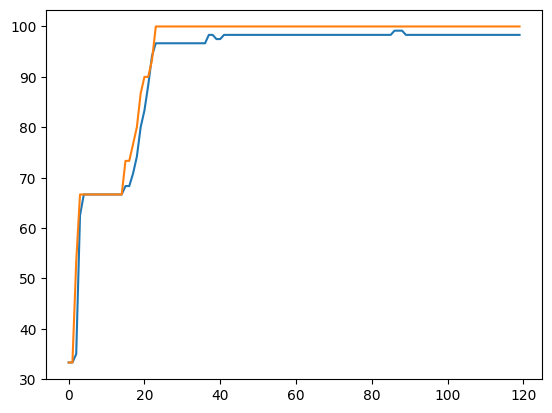

In [235]:
plt.plot(train_acc_list)
plt.plot(test_acc_list)
plt.show()

In [236]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("Train labels:", torch.unique(y_train, return_counts=True))
print("Test labels:", torch.unique(y_test, return_counts=True))

Train shape: torch.Size([120, 4])
Test shape: torch.Size([30, 4])
Train labels: (tensor([0, 1, 2]), tensor([40, 40, 40]))
Test labels: (tensor([0, 1, 2]), tensor([10, 10, 10]))


In [237]:
with torch.no_grad():
    y_train_pred = model(X_train).argmax(dim=1)

    wrong = (y_train_pred != y_train)

    print("Yanlış tahmin sayısı:", wrong.sum().item())
    print("Yanlış örneklerin indeksleri:",
          torch.where(wrong)[0])

Yanlış tahmin sayısı: 2
Yanlış örneklerin indeksleri: tensor([ 7, 64])


In [238]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [265]:
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])
new_sample_tensor = torch.tensor(new_sample, dtype=torch.float32)
model.eval()
with torch.inference_mode():
  sample_logit = model(new_sample_tensor)
  probs = torch.softmax(sample_logit, dim=1)
  index = torch.argmax(probs, dim=1)
  category_predicted = le.inverse_transform(index)


In [242]:
category_predicted

array(['Iris-setosa'], dtype=object)

In [243]:
df["Species"].unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [244]:
df[df["Species"] == "Iris-virginica"].head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
100,6.3,3.3,6.0,2.5,Iris-virginica
101,5.8,2.7,5.1,1.9,Iris-virginica
102,7.1,3.0,5.9,2.1,Iris-virginica
103,6.3,2.9,5.6,1.8,Iris-virginica
104,6.5,3.0,5.8,2.2,Iris-virginica


In [245]:
sample2 = np.array([[5.8, 2.7, 5.0, 2.1]])
model.eval()
with torch.inference_mode():
  sample_logits = model(torch.tensor(sample2, dtype=torch.float32))
  sample_probs = torch.softmax(sample_logits, dim=1)
  sample_pred = torch.argmax(sample_probs, dim=1)
  sample2_prediction = le.inverse_transform(sample_pred)
  print(sample2_prediction)


['Iris-virginica']


In [246]:
!pip install torchmetrics

In [247]:
from torchmetrics.classification import MulticlassAccuracy

In [248]:
accuracy = MulticlassAccuracy(num_classes=3)

In [249]:
epochs = 200
model2 = IrisClassifier()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model2.parameters(), lr=0.01)

for epoch in range(epochs):
  model2.train()
  logits = model2(X_train)
  loss = loss_fn(logits, y_train)

  pred = torch.softmax(logits, dim=1).argmax(dim=1)
  acc = accuracy(pred, y_train).item() * 100

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  model2.eval()
  with torch.inference_mode():
    test_logits = model2(X_test)
    test_loss = loss_fn(test_logits, y_test)
    test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
    test_acc = accuracy(test_pred, y_test).item() * 100

  if epoch % 10 == 0:
    print(f"epoch: {epoch}, Train Loss: {loss}, Train Accuracy: {acc}, Test Loss: {test_loss}, Test Accuracy: {test_acc}")



epoch: 0, Train Loss: 1.0912139415740967, Train Accuracy: 33.33333432674408, Test Loss: 1.0421444177627563, Test Accuracy: 33.33333432674408
epoch: 10, Train Loss: 0.8166223168373108, Train Accuracy: 66.66666865348816, Test Loss: 0.7832828760147095, Test Accuracy: 66.66666865348816
epoch: 20, Train Loss: 0.5228884816169739, Train Accuracy: 67.5000011920929, Test Loss: 0.5029076337814331, Test Accuracy: 73.33333492279053
epoch: 30, Train Loss: 0.3800964057445526, Train Accuracy: 88.33333253860474, Test Loss: 0.37401244044303894, Test Accuracy: 89.99999761581421
epoch: 40, Train Loss: 0.2606261074542999, Train Accuracy: 97.50000238418579, Test Loss: 0.2621873617172241, Test Accuracy: 93.33333969116211
epoch: 50, Train Loss: 0.15996596217155457, Train Accuracy: 96.66666388511658, Test Loss: 0.17520682513713837, Test Accuracy: 93.33333969116211
epoch: 60, Train Loss: 0.10506100207567215, Train Accuracy: 98.33333492279053, Test Loss: 0.12497390061616898, Test Accuracy: 96.66666984558105
epo

In [250]:
from torchmetrics.classification import MulticlassConfusionMatrix

In [251]:
confusion_matrix = MulticlassConfusionMatrix(num_classes=3)

In [252]:
print("test data confusion matrix: \n\n", confusion_matrix(test_pred, y_test))

test data confusion matrix: 

 tensor([[10,  0,  0],
        [ 0, 10,  0],
        [ 0,  0, 10]])


In [253]:
print("train data confusion matrix: \n\n", confusion_matrix(pred, y_train))

train data confusion matrix: 

 tensor([[40,  0,  0],
        [ 0, 39,  1],
        [ 0,  1, 39]])


In [254]:
from torchmetrics.utilities.plot import plot_confusion_matrix

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

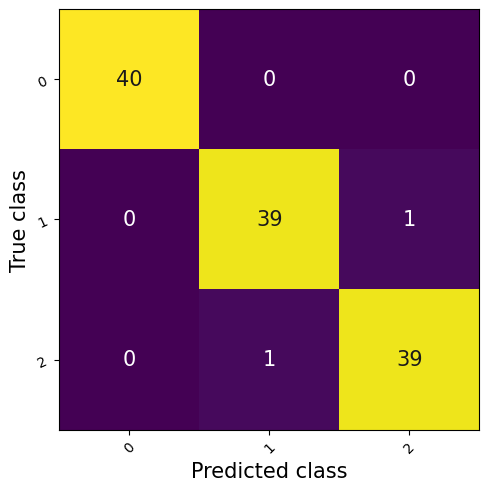

In [255]:
plot_confusion_matrix(confusion_matrix(pred, y_train))

In [256]:
from pathlib import Path

In [257]:
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "iris_classification_nn_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

In [258]:
MODEL_SAVE_PATH

PosixPath('models/iris_classification_nn_model.pth')

In [259]:
torch.save(obj=model2.state_dict(), f=MODEL_SAVE_PATH)

In [260]:
model2.state_dict()

OrderedDict([('linear_layer_stack.0.weight',
              tensor([[ 0.3299,  0.3517,  0.8502,  0.9589],
                      [ 0.0422,  0.0620,  0.3470,  1.4099],
                      [-0.2891,  0.1445,  0.0400, -0.1985],
                      [-0.2734, -0.1104,  0.0807,  0.1326],
                      [-0.2839,  0.2810, -0.3613, -0.1688],
                      [ 0.4001,  0.4892, -0.6131, -0.4140],
                      [-0.1603,  0.4105, -0.4367,  0.0870],
                      [ 1.0651,  0.6732, -0.3644, -0.5421],
                      [ 0.1684,  0.1817,  0.7943,  0.8473],
                      [-0.4031,  0.1751, -0.4706,  0.2612],
                      [ 0.5984,  0.8179, -0.7272, -0.5188],
                      [-0.2249, -0.3975,  0.2664, -0.1681],
                      [-0.0923,  0.7867, -0.1920, -0.3911],
                      [ 0.0332, -0.1233,  0.8310,  0.4264],
                      [-0.1333,  0.2220, -0.4308,  0.1560],
                      [-0.1584, -0.3601,  0.3083, -0.27

In [262]:
torch.load(MODEL_SAVE_PATH)

OrderedDict([('linear_layer_stack.0.weight',
              tensor([[ 0.3299,  0.3517,  0.8502,  0.9589],
                      [ 0.0422,  0.0620,  0.3470,  1.4099],
                      [-0.2891,  0.1445,  0.0400, -0.1985],
                      [-0.2734, -0.1104,  0.0807,  0.1326],
                      [-0.2839,  0.2810, -0.3613, -0.1688],
                      [ 0.4001,  0.4892, -0.6131, -0.4140],
                      [-0.1603,  0.4105, -0.4367,  0.0870],
                      [ 1.0651,  0.6732, -0.3644, -0.5421],
                      [ 0.1684,  0.1817,  0.7943,  0.8473],
                      [-0.4031,  0.1751, -0.4706,  0.2612],
                      [ 0.5984,  0.8179, -0.7272, -0.5188],
                      [-0.2249, -0.3975,  0.2664, -0.1681],
                      [-0.0923,  0.7867, -0.1920, -0.3911],
                      [ 0.0332, -0.1233,  0.8310,  0.4264],
                      [-0.1333,  0.2220, -0.4308,  0.1560],
                      [-0.1584, -0.3601,  0.3083, -0.27

In [263]:
loaded_model = IrisClassifier()

In [264]:
loaded_model.load_state_dict(torch.load(MODEL_SAVE_PATH))

<All keys matched successfully>

In [266]:
new_sample = np.array([[5.1, 3.5, 1.4, 0.2]])
new_sample_tensor = torch.tensor(new_sample, dtype=torch.float32)
loaded_model.eval()
with torch.inference_mode():
  sample_logit = loaded_model(new_sample_tensor)
  probs = torch.softmax(sample_logit, dim=1)
  index = torch.argmax(probs, dim=1)
  category_predicted = le.inverse_transform(index)

In [268]:
category_predicted[0]

'Iris-setosa'